# 02 · Statistical inference

The EDA showed *patterns*; this notebook asks which of them are **statistically reliable**, how large they are, and whether they survive adjustment for other variables.

Design choices:

* **Effect sizes first, p-values second.** With ~3,000 enrollments almost any difference is "significant"; the question is how big it is.
* **Multiple testing.** ~30 features are tested at once, so p-values are Holm-adjusted.
* **Non-independence.** Students contribute ~5 enrollments each. Univariate tests ignore that, so the multivariable models use **cluster-robust standard errors by student** and **mixed models** with student/course random intercepts.
* **Point-in-time features.** Associations are reported with features as known at the end of the course (day 60) and, for the early-warning question, at day 30.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.multitest import multipletests

from early_warning.config import load_config
from early_warning.features.build import FEATURE_GROUPS, FEATURES
from early_warning.viz import FAIL, NEUTRAL, PASS, save, set_style

set_style()
cfg = load_config()
d60 = pd.read_parquet(cfg.path("processed_dir") / "features_day60.parquet")
d30 = pd.read_parquet(cfg.path("processed_dir") / "features_day30.parquet")
print(d60.shape, f"failure rate {d60.failed.mean():.1%}")

(2964, 37) failure rate 5.3%


## 1. Univariate differences: failed vs passed

Mann–Whitney U test per feature (no normality assumption) with the **rank-biserial correlation** as effect size: *r* = P(failed > passed) − P(failed < passed), in [−1, 1]. Negative *r* means lower values among students who fail. 95% CIs by bootstrap (students resampled).

In [2]:
rng = np.random.default_rng(42)
users = d60["user_uuid"].unique()
idx_by_user = d60.groupby("user_uuid").indices


def rank_biserial(x_fail, x_pass):
    u = stats.mannwhitneyu(x_fail, x_pass, alternative="two-sided").statistic
    return 2 * u / (len(x_fail) * len(x_pass)) - 1


rows = []
boot_idx = [
    np.concatenate([idx_by_user[u] for u in rng.choice(users, len(users))]) for _ in range(300)
]
for f in FEATURES:
    sub = d60[[f, "failed"]].dropna()
    xf, xp = sub.loc[sub.failed == 1, f], sub.loc[sub.failed == 0, f]
    if xf.nunique() + xp.nunique() < 3:
        continue
    p = stats.mannwhitneyu(xf, xp, alternative="two-sided").pvalue
    r = rank_biserial(xf, xp)
    bs = []
    for ix in boot_idx:
        b = d60.iloc[ix][[f, "failed"]].dropna()
        bf, bp = b.loc[b.failed == 1, f], b.loc[b.failed == 0, f]
        if len(bf) > 5 and len(bp) > 5:
            bs.append(rank_biserial(bf, bp))
    rows.append(
        {
            "feature": f,
            "n": len(sub),
            "median_failed": xf.median(),
            "median_passed": xp.median(),
            "rank_biserial": r,
            "ci_low": np.quantile(bs, 0.025),
            "ci_high": np.quantile(bs, 0.975),
            "p": p,
        }
    )
uni = pd.DataFrame(rows)
uni["p_holm"] = multipletests(uni["p"], method="holm")[1]
uni["group"] = uni["feature"].map({f: g for g, fs in FEATURE_GROUPS.items() for f in fs})
uni = uni.sort_values("rank_biserial")
uni.round(3)

,feature,n,median_failed,median_passed,rank_biserial,ci_low,ci_high,p,p_holm,group
29,mean_exam_grade,2758,5.000,7.500,-0.788,-0.834,-0.734,0.000,0.000,exams
24,grade_INT,274,4.000,6.000,-0.742,-0.850,-0.618,0.000,0.000,exams
30,min_exam_grade,2758,4.000,7.000,-0.727,-0.779,-0.669,0.000,0.000,exams
22,grade_R1,167,4.000,8.000,-0.727,-0.918,-0.448,0.000,0.000,exams
27,best_first_partial,2690,5.000,8.000,-0.676,-0.742,-0.598,0.000,0.000,exams
28,best_second_partial,2693,5.000,8.000,-0.669,-0.734,-0.599,0.000,0.000,exams
21,grade_P2,2664,5.000,8.000,-0.667,-0.730,-0.597,0.000,0.000,exams
20,grade_P1,2634,5.000,7.000,-0.648,-0.724,-0.574,0.000,0.000,exams
4,submission_rate,2908,0.750,1.000,-0.461,-0.568,-0.353,0.000,0.000,engagement
2,n_submissions,2964,6.000,8.000,-0.415,-0.517,-0.302,0.000,0.000,engagement


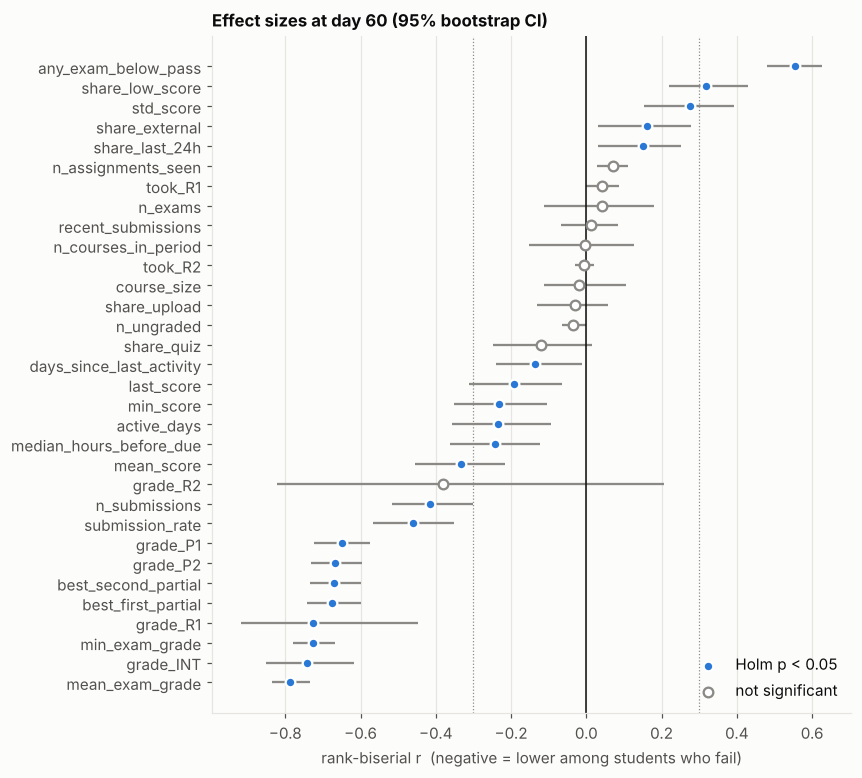

In [3]:
plot = uni.sort_values("rank_biserial", ascending=True)
fig, ax = plt.subplots(figsize=(7.5, 8))
y = np.arange(len(plot))
sig = plot["p_holm"] < 0.05
ax.hlines(y, plot["ci_low"], plot["ci_high"], color=NEUTRAL, lw=1.5)
ax.scatter(
    plot.loc[sig, "rank_biserial"],
    y[sig.values],
    color=PASS,
    s=40,
    zorder=3,
    label="Holm p < 0.05",
    edgecolor="white",
    linewidth=1.5,
)
ax.scatter(
    plot.loc[~sig, "rank_biserial"],
    y[~sig.values],
    facecolor="white",
    edgecolor=NEUTRAL,
    s=40,
    zorder=3,
    label="not significant",
    linewidth=1.5,
)
ax.axvline(0, color="#0b0b0b", lw=1)
for v in (-0.3, 0.3):
    ax.axvline(v, color=NEUTRAL, lw=0.8, ls=":")
ax.set_yticks(y, plot["feature"])
ax.set_xlabel("rank-biserial r  (negative = lower among students who fail)")
ax.set_title("Effect sizes at day 60 (95% bootstrap CI)")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
save(fig, "02_effect_sizes")

**Reading.** Exam-derived features have the largest effects (|r| ≈ 0.65–0.79). Among the behavioural features, **volume** (submission rate r ≈ −0.46, number of submissions r ≈ −0.42) and **score quality** (mean score r ≈ −0.33, share of low scores r ≈ +0.32) are medium-sized. **Timing** is a smaller but real signal: students who fail submit closer to the deadline (median margin ~175 h vs ~290 h). Workload (`n_courses_in_period`) and course size show no univariate difference. Dotted lines mark |r| = 0.3, a conventional "medium" effect.

## 2. Monotonic association with the final grade (Spearman)

In [4]:
rows = []
for f in FEATURES:
    sub = d60[[f, "final_grade"]].dropna()
    if sub[f].nunique() < 3:
        continue
    rho, p = stats.spearmanr(sub[f], sub["final_grade"])
    rows.append({"feature": f, "n": len(sub), "spearman_rho": rho, "p": p})
sp = pd.DataFrame(rows)
sp["p_holm"] = multipletests(sp["p"], method="holm")[1]
sp.sort_values("spearman_rho", key=abs, ascending=False).round(3).head(15)

,feature,n,spearman_rho,p,p_holm
27,mean_exam_grade,2758,0.903,0.0,0.0
22,grade_R1,167,0.861,0.0,0.0
24,grade_INT,274,0.856,0.0,0.0
25,best_first_partial,2690,0.808,0.0,0.0
28,min_exam_grade,2758,0.800,0.0,0.0
26,best_second_partial,2693,0.798,0.0,0.0
23,grade_R2,94,0.794,0.0,0.0
21,grade_P2,2664,0.777,0.0,0.0
20,grade_P1,2634,0.759,0.0,0.0
12,mean_score,2938,0.309,0.0,0.0


## 3. Categorical signals: make-up exams and failed partials

In [5]:
def odds_ratio_table(var):
    tab = pd.crosstab(d60[var], d60["failed"]).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
    t2 = sm.stats.Table2x2(tab.values[::-1, ::-1])  # rows: exposed first; cols: failed first
    lo, hi = t2.oddsratio_confint()
    _, p = stats.fisher_exact(tab.values)
    rate = tab[1] / tab.sum(axis=1)
    return {
        "variable": var,
        "fail_rate_if_0": rate[0],
        "fail_rate_if_1": rate[1],
        "odds_ratio": t2.oddsratio,
        "or_ci_low": lo,
        "or_ci_high": hi,
        "fisher_p": p,
    }


d60["any_exam_below_pass_filled"] = d60["any_exam_below_pass"].fillna(0)
pd.DataFrame(
    [odds_ratio_table(v) for v in ["took_R1", "took_R2", "any_exam_below_pass_filled"]]
).round(3)

,variable,fail_rate_if_0,fail_rate_if_1,odds_ratio,or_ci_low,or_ci_high,fisher_p
0,took_R1,0.050,0.090,1.859,1.065,3.244,0.047
1,took_R2,0.053,0.043,0.795,0.288,2.192,0.817
2,any_exam_below_pass_filled,0.027,0.230,10.598,7.558,14.861,0.000


Having **any exam below 5** multiplies the odds of failing the course by ~10.6 (95% CI 7.6–14.9): 23% of those students fail, against 2.7% of the rest. Taking the first make-up exam is only modestly associated (OR ≈ 1.9, borderline). The second make-up shows no association, probably because students who reach it and pass it have already recovered. "Any exam below 5" is a simple, interpretable rule that teachers can act on without a model.

## 4. How much of the variance is the *student* and how much the *course*?

Intraclass correlation (ICC) from random-intercept models of the final grade. A high student ICC confirms that rows of the same student are correlated, which justifies grouped validation; the course ICC says how much "which course" matters.

In [6]:
def icc(group):
    m = smf.mixedlm("final_grade ~ 1", d60, groups=d60[group]).fit(reml=True)
    var_g = float(m.cov_re.iloc[0, 0])
    var_e = m.scale
    return {
        "grouping": group,
        "var_between": var_g,
        "var_within": var_e,
        "ICC": var_g / (var_g + var_e),
    }


pd.DataFrame([icc("user_uuid"), icc("course_uuid")]).round(3)

,grouping,var_between,var_within,ICC
0,user_uuid,1.358,1.556,0.466
1,course_uuid,0.378,2.589,0.127


## 5. Does engagement add information *beyond* the exams?

OLS of the final grade at day 60 with **cluster-robust (by student) standard errors**, on standardized predictors (coefficients = grade points per 1 SD). Model A uses exams only; Model B adds assignment behaviour. If engagement only mirrored exam performance, its coefficients would vanish in Model B.

In [7]:
cols_exam = ["mean_exam_grade", "took_R1", "took_R2"]
cols_eng = ["mean_score", "share_low_score", "n_submissions", "active_days", "n_courses_in_period"]
df = d60[["user_uuid", "final_grade"] + cols_exam + cols_eng].dropna().copy()
z = df[cols_exam + cols_eng]
df[cols_exam + cols_eng] = (z - z.mean()) / z.std()


def fit(cols):
    X = sm.add_constant(df[cols])
    return sm.OLS(df["final_grade"], X).fit(
        cov_type="cluster", cov_kwds={"groups": pd.factorize(df["user_uuid"])[0]}
    )


mA, mB = fit(cols_exam), fit(cols_exam + cols_eng)
print(
    f"n = {len(df):,} | R2 exams only = {mA.rsquared:.3f} | R2 exams + engagement = {mB.rsquared:.3f}"
)
coef = pd.DataFrame(
    {"coef": mB.params, "ci_low": mB.conf_int()[0], "ci_high": mB.conf_int()[1], "p": mB.pvalues}
).drop("const")
coef.round(3)

n = 2,749 | R2 exams only = 0.758 | R2 exams + engagement = 0.769


,coef,ci_low,ci_high,p
mean_exam_grade,1.416,1.356,1.475,0.000
took_R1,0.090,0.047,0.133,0.000
took_R2,0.085,0.045,0.125,0.000
mean_score,0.003,-0.050,0.057,0.910
share_low_score,-0.122,-0.185,-0.059,0.000
n_submissions,0.086,0.046,0.127,0.000
active_days,0.064,0.029,0.100,0.000
n_courses_in_period,-0.004,-0.045,0.038,0.861


## 6. Early warning: what predicts failure at day 30?

Logistic regression for `failed` with features known on day 30, with cluster-robust SEs. By day 30, half of the enrollments have **not yet taken the first partial**, so its grade is entered together with a "taken" indicator (and imputed at the mean when missing). Odds ratios are per 1 SD.

In [8]:
e = d30[
    [
        "user_uuid",
        "failed",
        "best_first_partial",
        "mean_score",
        "share_low_score",
        "n_submissions",
        "submission_rate",
        "days_since_last_activity",
        "n_courses_in_period",
    ]
].copy()
e["first_partial_taken"] = e["best_first_partial"].notna().astype(int)
e["best_first_partial"] = e["best_first_partial"].fillna(e["best_first_partial"].mean())
for c in ["mean_score", "share_low_score", "submission_rate"]:
    e[c] = e[c].fillna(e[c].median())
num = [
    "best_first_partial",
    "mean_score",
    "share_low_score",
    "n_submissions",
    "submission_rate",
    "days_since_last_activity",
    "n_courses_in_period",
]
e[num] = (e[num] - e[num].mean()) / e[num].std()
X = sm.add_constant(e[num + ["first_partial_taken"]])
logit = sm.GLM(e["failed"], X, family=sm.families.Binomial()).fit(
    cov_type="cluster", cov_kwds={"groups": pd.factorize(e["user_uuid"])[0]}
)
orr = pd.DataFrame(
    {
        "odds_ratio": np.exp(logit.params),
        "ci_low": np.exp(logit.conf_int()[0]),
        "ci_high": np.exp(logit.conf_int()[1]),
        "p": logit.pvalues,
    }
).drop("const")
orr.round(3)

,odds_ratio,ci_low,ci_high,p
best_first_partial,0.431,0.344,0.541,0.000
mean_score,0.809,0.659,0.993,0.043
share_low_score,1.125,0.927,1.365,0.234
n_submissions,0.836,0.588,1.187,0.316
submission_rate,0.691,0.468,1.020,0.063
days_since_last_activity,1.199,1.055,1.362,0.005
n_courses_in_period,1.228,1.003,1.504,0.047
first_partial_taken,0.295,0.164,0.530,0.000


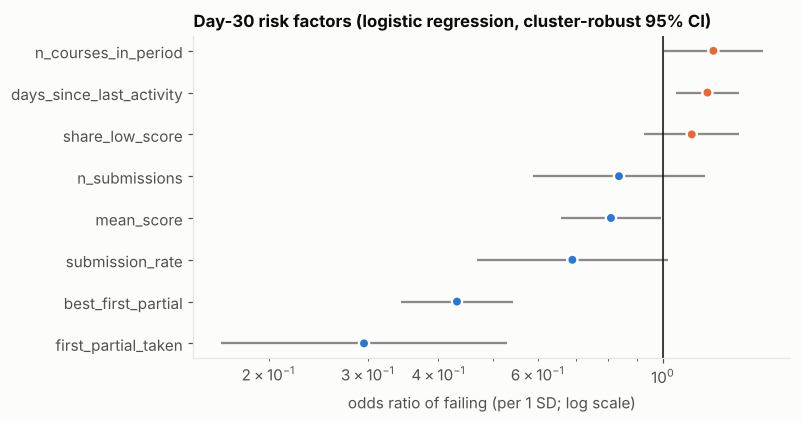

In [9]:
o = orr.sort_values("odds_ratio")
fig, ax = plt.subplots(figsize=(7, 3.8))
y = np.arange(len(o))
ax.hlines(y, o["ci_low"], o["ci_high"], color=NEUTRAL, lw=1.5)
colors = [FAIL if v > 1 else PASS for v in o["odds_ratio"]]
ax.scatter(o["odds_ratio"], y, color=colors, s=45, zorder=3, edgecolor="white", linewidth=1.5)
ax.axvline(1, color="#0b0b0b", lw=1)
ax.set_xscale("log")
ax.set_yticks(y, o.index)
ax.set_xlabel("odds ratio of failing (per 1 SD; log scale)")
ax.set_title("Day-30 risk factors (logistic regression, cluster-robust 95% CI)")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
save(fig, "02_day30_odds_ratios")

**Reading.** Adding behaviour to the exams raises R² only from 0.758 to 0.769. The *mean* assignment score becomes redundant once exams are known (its coefficient is ~0), but the **share of low scores**, the **number of submissions** and **active days** remain significant. They are small effects (≈0.06–0.12 grade points per SD), yet real.

**Day 30 (Section 6).** The first-partial grade is the strongest factor: each SD lower roughly doubles the odds of failing (OR 0.43 per SD higher). Lower assignment scores, longer inactivity and a heavier course load also raise the risk. Having already sat the first partial by day 30 goes with lower risk, which may reflect course pacing or student organization rather than a causal effect.

## 7. Conclusions

1. **Exams dominate.** Partial exams explain ~76% of the final-grade variance. Any exam below 5 is a strong, interpretable red flag (OR ≈ 10.6).
2. **Behaviour adds a little beyond exams.** Submission volume, activity and the share of low scores stay significant after adjusting for exams; the mean score does not.
3. **Student matters more than course.** ICC ≈ 0.47 by student vs ≈ 0.13 by course, which justifies grouping by student in every validation split.
4. **By day 30 there is actionable signal:** the first-partial grade, assignment scores, inactivity streaks and workload.
5. **Caveat:** these are associations in observational data. A low score may be a symptom rather than a cause, so interventions should be evaluated experimentally before claiming impact.